# 08b · ¿Por qué al artículo "le funciona"? Su método con sus propios datos
**Proyecto Integrador ML2 — Entrega final · Predicción de la TRM**

**Pregunta.** Con los mismos tres algoritmos, el artículo base (Eslami Ghayour y Yousefi, 2023) reporta R² de 0,76 a 0,99 en cinco pares de divisas, mientras que con la TRM el método tal cual falló (notebook 04) y, corregido, solo explica ~2 % del movimiento diario (notebooks 05–08). ¿Es que a ellos los modelos les funcionan mejor, o es otra cosa?

**Qué se hace.** Con los datos que el autor publicó en su repositorio (cinco pares, precio de cierre diario, 2003–2023):
1. Se descargan y congelan con MD5 (fijados a un commit del repositorio) y se revisa su calidad.
2. Se aplica **su método tal cual**, igual que en el notebook 04: precio en nivel, rezagos 1, 5 y 10, MinMax en variables y objetivo, partición cronológica 80/20 y configuración por defecto. Al lado: **copiar el precio de hoy** (sin modelo) y lo que el artículo publicó.
3. Se aplica **la misma corrección que hicimos con la TRM**: predecir el retorno logarítmico del día siguiente, con la regresión lineal y los tres boosting con los hiperparámetros congelados de la Entrega 2.
4. Se compara la TRM con sus pares usando **exactamente las mismas medidas**.

**Supuestos declarados.** El artículo no describe sus variables ni si su 80/20 es cronológico, y el repositorio no tiene código. Se usa la misma lectura que en el notebook 04 (rezagos 1, 5 y 10 del precio en nivel; partición cronológica). La TRM entra con el **desarrollo** (2003–2022), igual que en el notebook 04: el test no se usa.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

from src import config as cfg
from src.descarga import FUENTES_ARTICULO, ARTICULO_RAW, descargar_articulo, guardar_articulo, leer_articulo, md5
from src.calidad import picos_de_un_dia
from src.modelos import crear_modelo
from src.graficos import estilo, guardar_figura, guardar_tabla, COLORES

estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
congelada = json.loads(cfg.CONFIG_CONGELADA.read_text(encoding="utf-8"))

## 1. Datos del artículo: descarga y congelamiento
Igual que con nuestras fuentes: si la copia ya existe, no se descarga y se verifica su MD5. Las URL están fijadas al commit `506912c` (14 de mayo de 2023) del repositorio del autor. El archivo `EU-C.csv` del repositorio es idéntico a `EU.csv` y no se usa.

In [2]:
RUTA_META = ARTICULO_RAW / "metadatos.json"
meta = json.loads(RUTA_META.read_text(encoding="utf-8")) if RUTA_META.exists() else {}
for par, info in FUENTES_ARTICULO.items():
    ruta = ARTICULO_RAW / info["archivo"]
    if ruta.exists() and par in meta:
        assert md5(ruta) == meta[par]["md5"], f"{ruta.name}: la copia congelada fue modificada"
    else:
        meta[par] = guardar_articulo(par, descargar_articulo(par))
ARTICULO_RAW.mkdir(parents=True, exist_ok=True)
RUTA_META.write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
display(pd.DataFrame(meta).T[["archivo", "filas", "fecha_min", "fecha_max", "md5"]])

,archivo,filas,fecha_min,fecha_max,md5
GBP/USD,GU.csv,5037,2003-12-01,2023-04-13,951ae1d756b76e4c1cdba413fb9ce23c
EUR/USD,EU.csv,5025,None,None,f9f672d28f257ec7045039e81de4be4a
AUD/USD,AU.csv,4401,2006-05-16,2023-04-13,730a7794a8964bd7e1884831200051d1
NZD/USD,NU.csv,5026,2003-12-01,2023-04-13,f6a170e6c2f3fdbb5322badd9d93f0a2
USD/CHF,UC.csv,5091,2003-09-17,2023-04-13,0a3e3521f423939e912722aef0837cf8


## 2. Calidad de sus datos
Se aplica la misma revisión de calidad del notebook 01. Además se buscan **picos de un día**: saltos de más de 5 % que se deshacen al día siguiente en al menos un 75 % (`src/calidad.py`, `picos_de_un_dia`). Un precio así no es un movimiento de mercado sino un dato mal registrado. Con un umbral de 4 % también se marcaban movimientos reales de la crisis de 2008 (en AUD/USD y en la propia TRM); con 5 % solo quedan los errores.

In [3]:
PARES = list(FUENTES_ARTICULO)
datos = pd.read_csv(cfg.DATA_PROC / "dataset.csv", parse_dates=["fecha"])
dev = datos[datos["muestra"] == "desarrollo"].reset_index(drop=True)          # el test de la TRM no se usa
crudas = {par: leer_articulo(par) for par in PARES}
crudas["TRM (desarrollo)"] = dev[["fecha", "trm"]].rename(columns={"trm": "valor"})
SERIES = PARES + ["TRM (desarrollo)"]

limpias, filas = {}, []
for nombre in SERIES:
    t = crudas[nombre]
    v = t["valor"]
    pico = picos_de_un_dia(v)
    limpia = v.where(~pico).ffill()                       # el pico se reemplaza por el último precio válido
    limpias[nombre] = limpia
    r, rl = np.log(v).diff(), np.log(limpia).diff()
    filas.append({"serie": nombre, "filas": len(v),
                  "periodo": "sin fechas en el archivo" if t["fecha"].isna().all()
                  else f"{t['fecha'].min().date()} a {t['fecha'].max().date()}",
                  "vacios": int(v.isna().sum()), "min": v.min(), "max": v.max(),
                  "picos_de_un_dia": int(pico.sum()),
                  "detalle_picos": "; ".join(f"fila {i}: {v[i - 1]:.4f} → {v[i]:.4f} → {v[i + 1]:.4f}" for i in v.index[pico]),
                  "memoria_1d_con_picos": r.autocorr(1), "memoria_1d_sin_picos": rl.autocorr(1),
                  "mayor_movimiento_real_pct": 100 * rl.abs().max()})
calidad = pd.DataFrame(filas).set_index("serie")
guardar_tabla(calidad, "tab13a_calidad_datos_articulo")
display(calidad.drop(columns="detalle_picos"))
for nombre, f in calidad.iterrows():
    if f["picos_de_un_dia"]:
        print(f"{nombre}: {f['detalle_picos']}")

,filas,periodo,vacios,min,max,picos_de_un_dia,memoria_1d_con_picos,memoria_1d_sin_picos,mayor_movimiento_real_pct
serie,,,,,,,,,
GBP/USD,5037,2003-12-01 a 2023-04-13,0,1.0728,2.1082,0,0.0227,0.0227,7.9085
EUR/USD,5025,sin fechas en el archivo,0,0.9596,1.5988,5,-0.1848,-0.0216,3.5522
AUD/USD,4401,2006-05-16 a 2023-04-13,0,0.5743,4.5700,1,-0.4815,-0.0519,9.0007
NZD/USD,5026,2003-12-01 a 2023-04-13,0,0.4928,0.8824,0,-0.0082,-0.0082,6.7956
USD/CHF,5091,2003-09-17 a 2023-04-13,0,0.7228,1.3858,1,-0.0392,-0.0076,17.6109
TRM (desarrollo),4320,2003-12-17 a 2022-03-01,0,"1,652.4100","4,153.9100",0,0.1655,0.1655,5.9307


EUR/USD: fila 1066: 1.4683 → 1.5571 → 1.4664; fila 1089: 1.4479 → 1.5571 → 1.4502; fila 1221: 1.4275 → 1.5050 → 1.4148; fila 1243: 1.3588 → 1.4957 → 1.3598; fila 1286: 1.2717 → 1.4918 → 1.2926
AUD/USD: fila 159: 0.7835 → 4.5700 → 0.7826
USD/CHF: fila 1399: 1.1712 → 1.0824 → 1.1672


## 3. Su método tal cual, con sus datos (y con la TRM)
Rezagos 1, 5 y 10 del precio en nivel, MinMax en variables y objetivo ajustado con el entrenamiento, partición cronológica 80/20, LightGBM, CatBoost y XGBoost con la configuración por defecto. Se usan los datos **tal como los publicó el autor** (con picos), que es lo que él usó. Al lado, dos referencias: **copiar el precio de hoy** y la regresión lineal sobre los mismos rezagos. Para la TRM se recupera exactamente la Tabla 4 de la Entrega 2 (comprobación).

In [4]:
def metodo_articulo(precio, precio_sig=None):
    '''Aplica el método del artículo tal cual a una serie de precios y lo compara con copiar el precio de hoy.

    Parámetros
    ----------
    precio : pd.Series
        Precio de cierre en orden cronológico, con índice 0, 1, …
    precio_sig : pd.Series o None, por defecto None
        Precio del día siguiente (el objetivo). Con None se usa precio.shift(-1); para la TRM se pasa
        `trm_sig`, como en el notebook 04, para recuperar exactamente sus cifras.

    Devuelve
    --------
    tuple[pd.DataFrame, dict]
        Métricas por modelo en el 20 % final (R² y RMSE en nivel, R² sobre retornos, predicción máxima)
        y un resumen de la partición (% de días de evaluación fuera del rango del entrenamiento).
    '''
    d = pd.DataFrame({"p1": precio, "p5": precio.shift(4), "p10": precio.shift(9),
                      "sig": precio.shift(-1) if precio_sig is None else precio_sig}).dropna().reset_index(drop=True)
    corte = int(round(len(d) * 0.8))
    tr, ev = d.iloc[:corte], d.iloc[corte:]
    X = ["p1", "p5", "p10"]
    modelos = {"LightGBM": LGBMRegressor(random_state=cfg.SEMILLA, verbose=-1),
               "CatBoost": CatBoostRegressor(random_seed=cfg.SEMILLA, verbose=0, allow_writing_files=False),
               "XGBoost": XGBRegressor(random_state=cfg.SEMILLA), "Lineal": LinearRegression()}
    real, hoy = ev["sig"].to_numpy(), ev["p1"].to_numpy()
    pred = {n: TransformedTargetRegressor(regressor=Pipeline([("minmax", MinMaxScaler()), ("modelo", m)]),
                                          transformer=MinMaxScaler()).fit(tr[X], tr["sig"]).predict(ev[X])
            for n, m in modelos.items()}
    pred["Copiar el precio de hoy"] = hoy
    filas = [{"modelo": n, "r2_nivel": r2_score(real, p), "rmse_nivel": np.sqrt(np.mean((real - p) ** 2)),
              "r2_retornos": r2_score(np.log(real / hoy), np.log(p / hoy)), "prediccion_maxima": p.max()}
             for n, p in pred.items()]
    fuera = ((ev["sig"] > tr["sig"].max()) | (ev["sig"] < tr["sig"].min())).mean()
    return pd.DataFrame(filas).set_index("modelo"), {"filas_entrenamiento": len(tr), "filas_evaluacion": len(ev),
                                                     "pct_evaluacion_fuera_de_rango": 100 * fuera,
                                                     "max_entrenamiento": tr["sig"].max(), "max_evaluacion": ev["sig"].max()}

tal_cual, particion = {}, {}
for nombre in SERIES:
    sig = dev["trm_sig"] if nombre.startswith("TRM") else None
    tal_cual[nombre], particion[nombre] = metodo_articulo(crudas[nombre]["valor"], sig)

t04 = pd.read_csv(cfg.TABLAS / "tab04_reproduccion_articulo.csv", index_col=0)
for alg in ["LightGBM", "CatBoost", "XGBoost"]:
    assert np.isclose(tal_cual["TRM (desarrollo)"].loc[alg, "rmse_nivel"], t04.loc[alg, "rmse_pesos"], rtol=1e-6)
print("Comprobación: con la TRM se recupera exactamente la Tabla 4 de la Entrega 2.")

t13b = pd.concat(tal_cual, names=["serie"])
guardar_tabla(t13b, "tab13b_metodo_articulo_tal_cual")
display(t13b[["r2_nivel", "rmse_nivel", "r2_retornos"]].unstack("modelo")["r2_nivel"])

Comprobación: con la TRM se recupera exactamente la Tabla 4 de la Entrega 2.


modelo,LightGBM,CatBoost,XGBoost,Lineal,Copiar el precio de hoy
serie,,,,,
GBP/USD,0.8911,0.8743,0.8610,0.9888,0.9888
EUR/USD,0.9226,0.9260,0.9291,0.9927,0.9930
AUD/USD,0.8884,0.9587,0.9588,0.8603,0.9855
NZD/USD,0.9850,0.9842,0.9832,0.9876,0.9876
USD/CHF,0.9794,0.9791,0.9771,0.9806,0.9807
TRM (desarrollo),-0.1456,-0.0422,-0.0505,0.9919,0.9919


### Lo que publicó el artículo (Tabla 1 del paper) frente a lo reproducido

In [5]:
PUBLICADO_R2 = {   # Tabla 1 de Eslami Ghayour y Yousefi (2023): R² en nivel
    "EUR/USD": {"XGBoost": 0.9254, "LightGBM": 0.9351, "CatBoost": 0.9223},
    "GBP/USD": {"XGBoost": 0.8921, "LightGBM": 0.8956, "CatBoost": 0.8657},
    "AUD/USD": {"XGBoost": 0.7621, "LightGBM": 0.9042, "CatBoost": 0.8257},
    "NZD/USD": {"XGBoost": 0.9822, "LightGBM": 0.9874, "CatBoost": 0.9824},
    "USD/CHF": {"XGBoost": 0.9738, "LightGBM": 0.9830, "CatBoost": 0.9745},
}
filas = []
for par in PARES:
    for alg in ["LightGBM", "CatBoost", "XGBoost"]:
        filas.append({"serie": par, "algoritmo": alg, "r2_publicado": PUBLICADO_R2[par][alg],
                      "r2_reproducido": tal_cual[par].loc[alg, "r2_nivel"],
                      "r2_copiar_precio_de_hoy": tal_cual[par].loc["Copiar el precio de hoy", "r2_nivel"]})
publicado = pd.DataFrame(filas).set_index(["serie", "algoritmo"])
publicado["publicado_menos_copiar"] = publicado["r2_publicado"] - publicado["r2_copiar_precio_de_hoy"]
guardar_tabla(publicado, "tab13c_publicado_vs_reproducido")
display(publicado)
gana_pub = publicado.groupby("serie")["r2_publicado"].idxmax().str[1]
gana_rep = publicado.groupby("serie")["r2_reproducido"].idxmax().str[1]
print("Ganador publicado:  ", gana_pub.to_dict())
print("Ganador reproducido:", gana_rep.to_dict())

r2_publicado  r2_reproducido  r2_copiar_precio_de_hoy  \
serie   algoritmo                                                          
GBP/USD LightGBM         0.8956          0.8911                   0.9888   
        CatBoost         0.8657          0.8743                   0.9888   
        XGBoost          0.8921          0.8610                   0.9888   
EUR/USD LightGBM         0.9351          0.9226                   0.9930   
        CatBoost         0.9223          0.9260                   0.9930   
        XGBoost          0.9254          0.9291                   0.9930   
AUD/USD LightGBM         0.9042          0.8884                   0.9855   
        CatBoost         0.8257          0.9587                   0.9855   
        XGBoost          0.7621          0.9588                   0.9855   
NZD/USD LightGBM         0.9874          0.9850                   0.9876   
        CatBoost         0.9824          0.9842                   0.9876   
        XGBoost          0.9822          0.9832                   0.9876   
USD/CHF LightGBM         0.9830          0.9794                   0.9807   
        CatBoost         0.9745          0.9791                   0.9807   
        XGBoost          0.9738          0.9771                   0.9807   

                   publicado_menos_copiar  
serie   algoritmo                          
GBP/USD LightGBM                  -0.0932  
        CatBoost                  -0.1231  
        XGBoost                   -0.0967  
EUR/USD LightGBM                  -0.0579  
        CatBoost                  -0.0707  
        XGBoost                   -0.0676  
AUD/USD LightGBM                  -0.0813  
        CatBoost                  -0.1598  
        XGBoost                   -0.2234  
NZD/USD LightGBM                  -0.0002  
        CatBoost                  -0.0052  
        XGBoost                   -0.0054  
USD/CHF LightGBM                   0.0023  
        CatBoost                  -0.0062  
        XGBoost                   -0.0069

Ganador publicado:   {'AUD/USD': 'LightGBM', 'EUR/USD': 'LightGBM', 'GBP/USD': 'LightGBM', 'NZD/USD': 'LightGBM', 'USD/CHF': 'LightGBM'}
Ganador reproducido: {'AUD/USD': 'XGBoost', 'EUR/USD': 'XGBoost', 'GBP/USD': 'LightGBM', 'NZD/USD': 'LightGBM', 'USD/CHF': 'LightGBM'}


## 4. La misma corrección que hicimos con la TRM: predecir el retorno
Objetivo: retorno logarítmico del día siguiente; variables: retornos de hace 1, 5 y 10 días; partición cronológica 80/20; regresión lineal y los tres boosting con los **hiperparámetros congelados de la Entrega 2** (configuración `solo_trm`). Aquí se usan las series **sin picos**, porque un retorno de +176 % por un dato mal registrado no es información del mercado.

In [6]:
def correccion_retornos(precio):
    '''Aplica a una serie de precios la corrección del proyecto: predecir el retorno del día siguiente.

    Parámetros
    ----------
    precio : pd.Series
        Precio de cierre limpio (sin picos), en orden cronológico.

    Devuelve
    --------
    pd.Series
        R² sobre retornos en el 20 % final para la regresión lineal y los tres boosting, y la memoria
        del retorno a un día (autocorrelación) en el 80 % inicial.
    '''
    r = np.log(precio).diff()
    d = pd.DataFrame({"r1": r, "r5": r.shift(4), "r10": r.shift(9), "y": r.shift(-1)}).dropna().reset_index(drop=True)
    corte = int(round(len(d) * 0.8))
    tr, ev = d.iloc[:corte], d.iloc[corte:]
    X = ["r1", "r5", "r10"]
    res = {"Lineal": r2_score(ev["y"], Pipeline([("escala", StandardScaler()), ("modelo", LinearRegression())])
                              .fit(tr[X], tr["y"]).predict(ev[X]))}
    for alg in cfg.MODELOS_BOOSTING:
        hp = congelada["modelos"][f"{alg} · solo_trm"]["hiperparametros"]
        m = crear_modelo(alg).set_params(**{f"modelo__{k}": v for k, v in hp.items()})
        res[alg] = r2_score(ev["y"], m.fit(tr[X], tr["y"]).predict(ev[X]))
    res["memoria_1d_entrenamiento"] = r.iloc[:corte].autocorr(1)
    return pd.Series(res)

t13d = pd.DataFrame({n: correccion_retornos(limpias[n]) for n in SERIES}).T
t13d.index.name = "serie"
guardar_tabla(t13d, "tab13d_retornos")
display(t13d)

,Lineal,LightGBM,CatBoost,XGBoost,memoria_1d_entrenamiento
serie,,,,,
GBP/USD,0.0013,-0.0022,-0.0048,-0.0157,0.0112
EUR/USD,-0.0044,-0.0125,-0.0068,-0.0100,-0.0326
AUD/USD,-0.0113,-0.0242,-0.0331,-0.0359,-0.0684
NZD/USD,-0.0018,-0.0096,-0.0063,-0.0049,-0.0097
USD/CHF,-0.0016,-0.0108,-0.0029,-0.0098,-0.0166
TRM (desarrollo),0.0141,0.0274,0.0346,0.0192,0.1739


## 5. La TRM frente a sus pares, con las mismas medidas

In [7]:
resumen = pd.DataFrame({
    "pct_evaluacion_fuera_de_rango": {n: particion[n]["pct_evaluacion_fuera_de_rango"] for n in SERIES},
    "r2_nivel_copiar_precio_de_hoy": {n: tal_cual[n].loc["Copiar el precio de hoy", "r2_nivel"] for n in SERIES},
    "r2_nivel_publicado_mejor": {n: max(PUBLICADO_R2[n].values()) if n in PUBLICADO_R2 else np.nan for n in SERIES},
    "r2_nivel_reproducido_mejor_boosting": {n: tal_cual[n].loc[["LightGBM", "CatBoost", "XGBoost"], "r2_nivel"].max() for n in SERIES},
    "r2_retornos_lineal": t13d["Lineal"], "r2_retornos_mejor_boosting": t13d[cfg.MODELOS_BOOSTING].max(axis=1),
    "memoria_1d": calidad["memoria_1d_sin_picos"], "picos_de_un_dia": calidad["picos_de_un_dia"],
})
resumen["boosting_menos_copiar"] = resumen["r2_nivel_reproducido_mejor_boosting"] - resumen["r2_nivel_copiar_precio_de_hoy"]
resumen.index.name = "serie"
guardar_tabla(resumen, "tab13_articulo_vs_trm")
display(resumen)

,pct_evaluacion_fuera_de_rango,r2_nivel_copiar_precio_de_hoy,r2_nivel_publicado_mejor,r2_nivel_reproducido_mejor_boosting,r2_retornos_lineal,r2_retornos_mejor_boosting,memoria_1d,picos_de_un_dia,boosting_menos_copiar
serie,,,,,,,,,
GBP/USD,11.1443,0.9888,0.8956,0.8911,0.0013,-0.0022,0.0227,0,-0.0977
EUR/USD,10.3689,0.9930,0.9351,0.9291,-0.0044,-0.0068,-0.0216,5,-0.0639
AUD/USD,0.9112,0.9855,0.9042,0.9588,-0.0113,-0.0242,-0.0519,1,-0.0267
NZD/USD,0.0000,0.9876,0.9874,0.9850,-0.0018,-0.0049,-0.0082,0,-0.0026
USD/CHF,0.0000,0.9807,0.9830,0.9794,-0.0016,-0.0029,-0.0076,1,-0.0013
TRM (desarrollo),59.0487,0.9919,NaN,-0.0422,0.0141,0.0346,0.1655,0,-1.0341


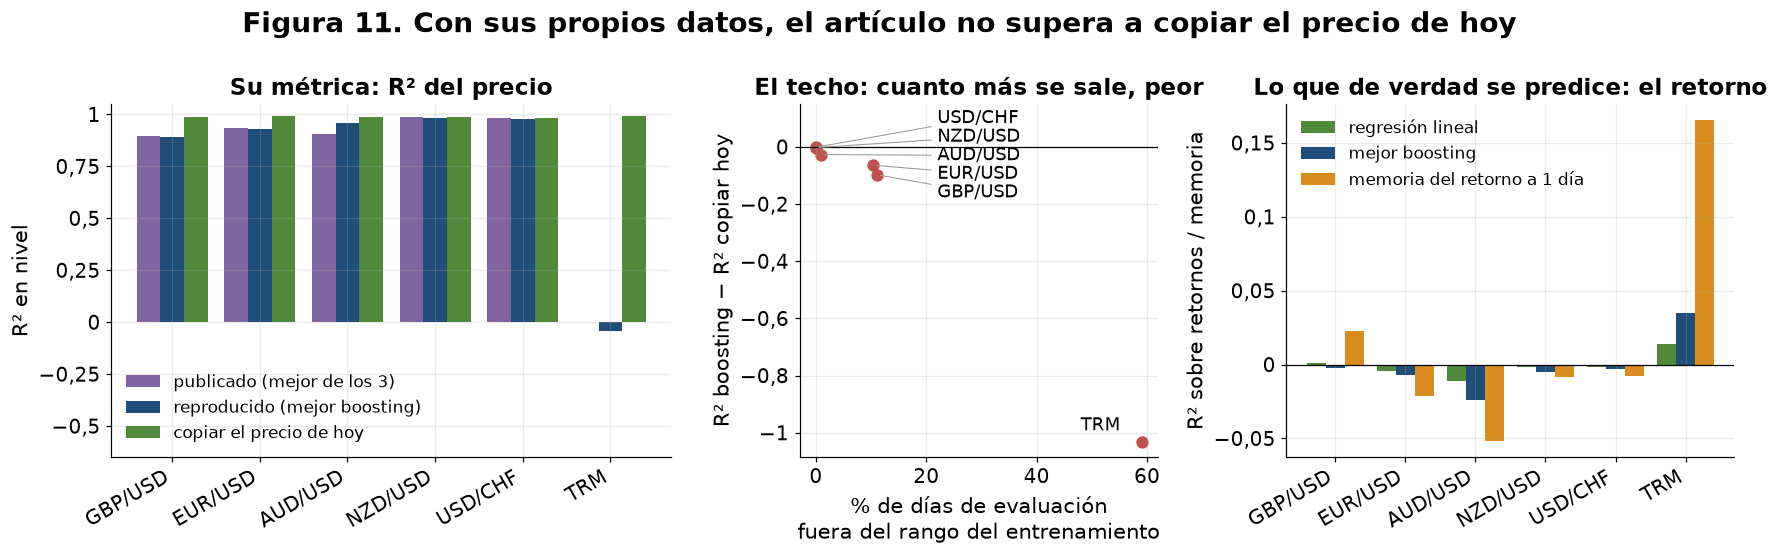

In [8]:
# Letra grande y coma decimal: esta figura se imprime a todo el ancho en el informe final.
from src.graficos import LETRA_GRANDE, coma_decimal
with plt.rc_context(LETRA_GRANDE):
    fig, ejes = plt.subplots(1, 3, figsize=(16, 5.2), gridspec_kw={"width_ratios": [5, 3.2, 4]})
    x = np.arange(len(SERIES)); etiquetas = [s.replace(" (desarrollo)", "") for s in SERIES]
    eje = ejes[0]
    for j, (col, etq, c) in enumerate([("r2_nivel_publicado_mejor", "publicado (mejor de los 3)", COLORES[3]),
                                       ("r2_nivel_reproducido_mejor_boosting", "reproducido (mejor boosting)", COLORES[0]),
                                       ("r2_nivel_copiar_precio_de_hoy", "copiar el precio de hoy", COLORES[2])]):
        eje.bar(x + (j - 1) * 0.27, resumen[col].clip(lower=-0.3), width=0.27, color=c, label=etq)
    eje.set(xticks=x, ylim=(-0.65, 1.05), ylabel="R² en nivel", title="Su métrica: R² del precio")
    eje.set_xticklabels(etiquetas, rotation=30, ha="right")
    eje.legend(frameon=False, loc="lower left", fontsize=11)
    coma_decimal(eje, "y")
    eje = ejes[1]
    eje.scatter(resumen["pct_evaluacion_fuera_de_rango"], resumen["boosting_menos_copiar"], color=COLORES[1], s=50)
    # Los cinco pares quedan casi en el mismo punto: etiquetas en columna, en el orden de su valor, con flecha.
    COLUMNA = {"USD/CHF": 0.10, "NZD/USD": 0.035, "AUD/USD": -0.03, "EUR/USD": -0.095, "GBP/USD": -0.16}
    for n, f in resumen.iterrows():
        punto = (f["pct_evaluacion_fuera_de_rango"], f["boosting_menos_copiar"])
        if n in COLUMNA:
            eje.annotate(n, punto, xytext=(22, COLUMNA[n]), textcoords="data", fontsize=12, va="center",
                         arrowprops={"arrowstyle": "-", "color": "0.6", "lw": 0.7})
        else:
            eje.annotate(n.replace(" (desarrollo)", ""), punto, xytext=(-40, 8), textcoords="offset points", fontsize=12)
    eje.axhline(0, color="k", lw=0.8)
    eje.set(xlabel="% de días de evaluación\nfuera del rango del entrenamiento", ylabel="R² boosting − R² copiar hoy",
            title="El techo: cuanto más se sale, peor")
    eje.set_ylim(top=0.15)
    coma_decimal(eje)
    eje = ejes[2]
    for j, (col, etq, c) in enumerate([("r2_retornos_lineal", "regresión lineal", COLORES[2]),
                                       ("r2_retornos_mejor_boosting", "mejor boosting", COLORES[0]),
                                       ("memoria_1d", "memoria del retorno a 1 día", COLORES[4])]):
        eje.bar(x + (j - 1) * 0.27, resumen[col], width=0.27, color=c, label=etq)
    eje.axhline(0, color="k", lw=0.8)
    eje.set(xticks=x, ylabel="R² sobre retornos / memoria", title="Lo que de verdad se predice: el retorno")
    eje.set_xticklabels(etiquetas, rotation=30, ha="right")
    eje.legend(frameon=False, fontsize=11)
    coma_decimal(eje, "y")
    fig.suptitle("Figura 11. Con sus propios datos, el artículo no supera a copiar el precio de hoy", fontweight="bold")
    fig.tight_layout()
    guardar_figura(fig, "fig11_articulo_vs_trm")
    plt.show()

## Lectura: por qué al artículo "le funciona"
**1. La reproducción es fiel (Tabla 13c).** Con sus datos y nuestra lectura de su método (rezagos 1, 5 y 10 en nivel, MinMax, 80/20 cronológico, configuración por defecto) salen casi los mismos R² que publicaron: GBP/USD con LightGBM 0,891 frente a 0,896; EUR/USD 0,92–0,93 en los tres; NZD/USD y USD/CHF dentro de ±0,01. La excepción es AUD/USD con CatBoost y XGBoost (0,96 reproducido frente a 0,83 y 0,76 publicados), sin código del autor no se puede saber por qué. Que los números calcen indica que su partición sí fue cronológica. Su conclusión de que "LightGBM es el mejor" no es robusta: en lo reproducido gana LightGBM en 3 pares y XGBoost en 2, con diferencias menores a 0,01.

**2. A ellos no les funciona mejor: su R² no supera a copiar el precio de hoy (Tabla 13, Figura 11 izquierda).** Copiar el precio de hoy, sin ningún modelo, da R² de 0,981 a 0,993 en sus cinco pares. El mejor boosting reproducido queda **por debajo** en los cinco (de −0,001 a −0,10), y lo que ellos publicaron también, salvo USD/CHF con LightGBM (+0,002). El R² ≈ 0,9 del artículo mide que el precio de mañana se parece al de hoy, no que el modelo prediga. La regresión lineal en nivel, igual que con la TRM, aprende a copiar el precio de hoy y empata con esa referencia.

**3. Por qué el método no se rompe con sus datos y sí con la TRM: el techo (Figura 11 centro).** Un árbol no puede predecir fuera del rango que vio. En sus pares, el periodo de evaluación casi no sale de ese rango: 0 % en NZD/USD y USD/CHF, 1 % en AUD/USD, 10–11 % en EUR/USD y GBP/USD. La TRM, en cambio, subió hasta salirse en el 59 % de los días. La pérdida frente a copiar el precio crece exactamente en ese orden: −0,003 y −0,001 (0 %), −0,03 (1 %), −0,06 y −0,10 (10–11 %) y **−1,03 en la TRM (59 %)**. **La diferencia está en los datos, no en los algoritmos.**

**4. Lo que de verdad se predice, el retorno: la TRM es la más predecible (Tabla 13d, Figura 11 derecha).** Con la misma corrección que hicimos (retorno del día siguiente, mismos hiperparámetros), en sus cinco pares el R² sobre retornos va de −0,04 a +0,001: **nadie predice la dirección de sus monedas**, y los boosting quedan por debajo de cero. La TRM es la única serie con R² positivo (0,014 la regresión lineal y hasta 0,035 el mejor boosting en este corte 80/20) y con memoria a un día (0,17 frente a −0,05 a +0,02). La razón ya se vio: la TRM es el **promedio** de las operaciones de un día, así que parte del movimiento de hoy aparece en el de mañana; los pares del artículo son precios de cierre, sin esa inercia.

**5. Sus datos tienen errores (Tabla 13a).** Hay 7 picos de un día: 5 en EUR/USD (saltos de +6 % a +16 % que se deshacen al día siguiente), 1 en AUD/USD (4,57 el 25 de diciembre de 2006, cuando valía 0,78) y 1 en USD/CHF (−7,9 % y +7,6 %). Producen la memoria negativa anómala de EUR/USD (−0,18) y AUD/USD (−0,48), que desaparece al quitarlos (−0,02 y −0,05). Además, el archivo de EUR/USD no trae fechas. El artículo no los menciona.

**En una frase:** al artículo no le funciona mejor; su métrica (R² del precio) premia la persistencia y sus monedas no salen del rango de entrenamiento. Medido con rigor, ni sus modelos ni los nuestros predicen la dirección más allá de la inercia de un día, y la TRM es la serie que más inercia tiene.